In [1]:
# Importing modules
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

In [2]:
# Reading lipid data
df = pd.read_csv("../data/lipid_data_original.tsv", sep="\t")

# Dataframe manipulation
new_df = df.T[0:]
new_df["Sample"] = new_df.index
new_df.rename({0: 'Class'}, axis=1, inplace=True)
new_df = new_df.reset_index(drop=True)
new_df.rename({idx:i for idx, i in enumerate(df["UHID"].to_numpy())}, axis=1, inplace=True)
lipid_df = new_df

# Reading clinical data
df = pd.read_csv("../data/clinical_data_original.tsv", sep="\t")

# Dataframe manipulation
new_df = df.T[1:]
new_df["Sample"] = new_df.index
new_df = new_df.reset_index(drop=True)
new_df.rename({idx:i for idx, i in enumerate(df["UHID"].to_numpy())}, axis=1, inplace=True)
clinical_df = new_df

# Merging both data
new_df = lipid_df.merge(clinical_df, on="Sample")

In [3]:
############################## Preprocessing ##############################

# Dropping non-numeric data
X = new_df.drop(["Class", "Group", "Sample"], axis=1)

# 1. Replace ' ' with NaN
X = X.replace(' ', np.nan)

# 2. Convert all columns to numeric
X = X.apply(pd.to_numeric, errors='coerce')

# 3. Removing features with >20% missing values
X = X.loc[:, X.isnull().mean() <= 0.20]

# 4. KNN imputation (filling missing values)
imputer = KNNImputer(n_neighbors=3)

# Final df after imputation
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
X["Samples"] = new_df["Sample"].to_numpy()
X["Class"] = new_df["Group"].to_numpy()
X["Batch"] = new_df["Class"].to_numpy()

# Shape after inputation and filtering
X.shape

(103, 870)

In [4]:
# Lipid data
X_lipid = X.drop(["Age","Sex","Weight","Height"], axis=1)

# Clinical data
X_clinical = X[["Samples", "Class", "Batch", "Age", "Sex", "Weight","Height"]]

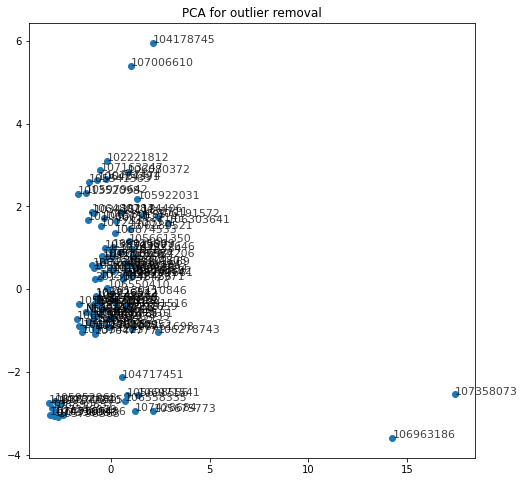

In [5]:
# PCA analysis for outliers identification

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_X_lipid = scaler.fit_transform(X_lipid.drop(["Class", "Batch", "Samples"], axis=1))

sample_list = X_lipid["Samples"].to_numpy()

pca = PCA(n_components=2) 
X_pca = pca.fit_transform(scaled_X_lipid)
X_pca = pd.DataFrame(data=X_pca, columns=["PC1", "PC2"])

plt.figure(figsize=[8, 8])
plt.scatter(X_pca["PC1"], X_pca["PC2"],)
for i, label in enumerate(sample_list):
    plt.text(X_pca["PC1"][i], X_pca["PC2"][i], label, fontsize=11, alpha=0.75)
plt.title("PCA for outlier removal")
plt.show()

In [6]:
# Removing outliers ['107358073', '106963186', '104178745', '107006610']
X_lipid = X_lipid[X_lipid['Samples'].isin(['107358073', '106963186', '104178745', '107006610']) == False]

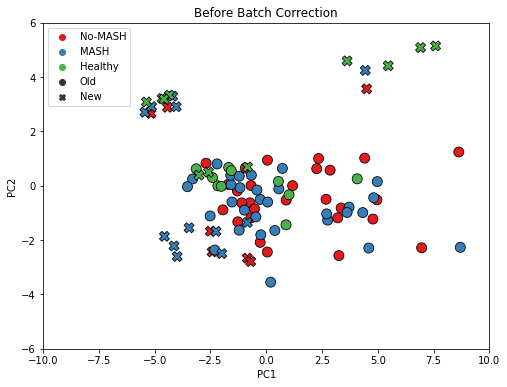

In [7]:
# PCA for observing batch effect

scaler = MinMaxScaler(feature_range=(0, 1))

pca = PCA(n_components=2)

scaled_data = scaler.fit_transform(X_lipid.drop(["Samples", "Class", "Batch"], axis=1))
batch_ = X_lipid["Batch"].to_numpy()
class_ = X_lipid["Class"].to_numpy()
sample_ = X_lipid["Samples"].to_numpy()

pca_data = pca.fit_transform(scaled_data)
pca_data = pd.DataFrame(pca_data, columns=["PC1", "PC2"])
pca_data["Samples"] = X_lipid["Samples"].to_numpy()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pca_data["PC1"],y=pca_data["PC2"], hue=class_, style=batch_, s=100, palette='Set1', edgecolor='k')
plt.xlim(-10, 10)
plt.ylim(-6, 6)
plt.title("Before Batch Correction")
plt.show()

In [8]:
# Saving imputed data for batch correction using MetaboAnalyst
X_lipid["Order"] = np.arange(1, 100)
X_lipid = X_lipid[X_lipid.columns[-4:].tolist() + X_lipid.columns[:-4].tolist()]
X_lipid = X_lipid.T
X_lipid.to_csv("../data/lipid_data_inputed.csv", quoting=False, header=False)

### Batch correction using [MetaboAnalyst](https://www.metaboanalyst.ca/MetaboAnalyst/upload/BatchUpload.xhtml)

1. Select: Upload a single merged file
2. Data format: Sample in columns
3. Correction method: automated (default)
4. Evaluation target: Samples
5. Missing value estimation: LoDs (1/5 of the minimum)
6. Choose lipid_data_inputed.csv 
7. Click on upload
8. Download the batch corrected data table and all the plots once the analysis is completed


**Plots from MetaboAnalyst batch correction:**
<div style="display: flex; justify-content: center; align-items: center; gap: 10px;">
  <img src="img/batch_0_distdpi72.png" width="30%">
  <img src="img/batch_0_dpi72.png" width="30%">
  <img src="img/batch_0_Trenddpi72.png" width="30%">
</div>

In [9]:
# Reading batch corrected lipid data
X_lipid = pd.read_csv("../data/MetaboAnalyst_batch_data.csv")

sample = [i.replace("X", "") for i in X_lipid["NAME"].to_numpy()]
sample = [i.replace(".", "-") for i in sample]

X_lipid = X_lipid.rename(columns={'NAME': 'Samples', 'CLASS': 'Class', 'Dataset':'Batch'})
X_lipid["Samples"] = sample

In [10]:
############################## Preprocessing ##############################

# Replacing 0 with NA
X_lat_na = X_lipid.drop(["Samples","Batch", "Class"], axis =1)
X_lat_na = X_lat_na.replace(0, np.nan)

# KNN imputation
imputer = KNNImputer(n_neighbors=3)
cols = X_lat_na.columns.to_numpy()
X_lat_imputed = pd.DataFrame(imputer.fit_transform(X_lat_na), columns=cols)
X_lat_imputed[["Samples","Batch", "Class"]] = X_lipid[["Samples","Batch", "Class"]]
X_lipid = X_lat_imputed

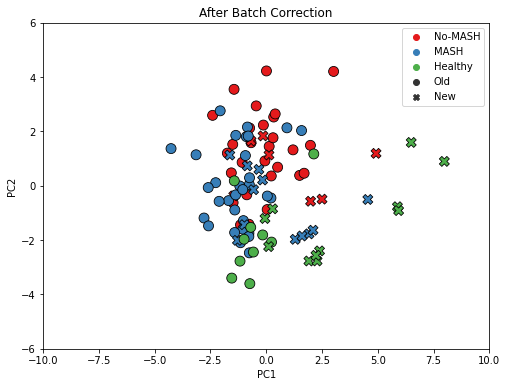

In [11]:
# PCA after batch correction + imputation

scaler = MinMaxScaler(feature_range=(0, 1))

pca = PCA(n_components=2)

scaled_data = scaler.fit_transform(X_lipid.drop(["Samples", "Class", "Batch"], axis=1))
batch_ = X_lipid["Batch"].to_numpy()
class_ = X_lipid["Class"].to_numpy()
sample_ = X_lipid["Samples"].to_numpy()

pca_data = pca.fit_transform(scaled_data)
pca_data = pd.DataFrame(pca_data, columns=["PC1", "PC2"])
pca_data["Samples"] = X_lipid["Samples"].to_numpy()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pca_data["PC1"],y=pca_data["PC2"], hue=class_, style=batch_, s=100, palette='Set1', edgecolor='k')
plt.xlim(-10, 10)
plt.ylim(-6, 6)
plt.title("After Batch Correction")
plt.show()

In [12]:
# Labels
y = X_lipid["Class"]

# Lipid data
X = X_lipid.drop(["Class", "Batch"], axis=1)

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y, shuffle=True)
X_train["Datatype"] = "Training"
X_test["Datatype"] = "Validation"
final_df = pd.concat([X_train, X_test]).reset_index(drop=True)
final_df["Class"] = y_train.to_list()+y_test.to_list()

In [13]:
# Saving final data for ML
final_df.to_csv("../data/final_data.tsv", quoting=False, index=False)